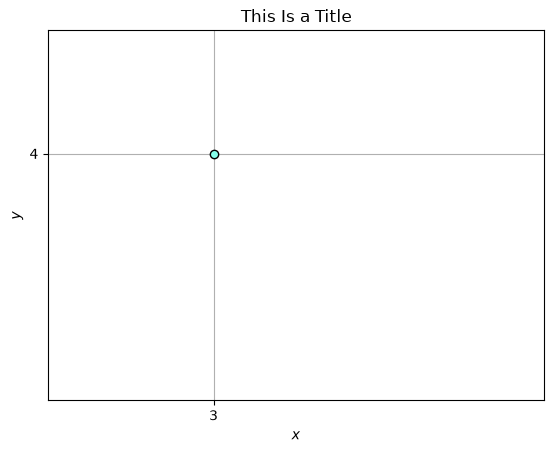

In [3]:
""" 
1 Take the point p(3, 4), and plot it as a circle (marker "o"). Make the edges of 
the marker show in black. Set the displayed data area ((𝑥min, 𝑥max), (𝑦min, 𝑦max)) to 
((2, 5), (2, 5)). Give the plot a title and name the x- and y-axis. Show only the x- 
and y-coordinates of the point in the x- and y-ticks. Add a data grid (plt.grid) to 
the plot.
"""

import matplotlib.pyplot as plt

plt.plot( 3, 4,
    marker = "o", markerfacecolor = "#85FFEB", markeredgecolor = "k"
)

plt.xlim((2, 5))
plt.ylim((2, 5))

plt.title("This Is a Title")
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.xticks((3,))
plt.yticks((4,))
plt.grid()


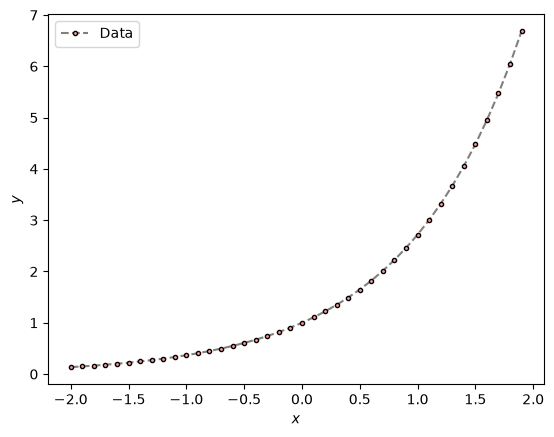

In [28]:
""" 
2 Take the below sequence of x- and y-data points and plot them as dots. Make the 
connection between the points a dashed gray line. Add axis-labels and a legend 
describing what can be seen.
"""

x = [x/10 for x in range(-20, 20)]
y = [
    0.13533528323661, 0.149568619222635, 0.165298888221586, 0.182683524052734, 0.201896517994655,
    0.223130160148429, 0.24659696394160, 0.27253179303401, 0.301194211912202, 0.332871083698079,
    0.367879441171442, 0.40656965974059, 0.449328964117221, 0.49658530379140, 0.54881163609402,
    0.60653065971263, 0.67032004603563, 0.74081822068171, 0.81873075307798, 0.90483741803595,
    1.0, 1.10517091807564, 1.22140275816016, 1.34985880757600, 1.49182469764127, 1.64872127070012,
    1.82211880039050, 2.01375270747047, 2.2255409284924, 2.459603111156, 2.7182818284590,
    3.00416602394643, 3.32011692273654, 3.66929666761924, 4.05519996684467, 4.48168907033806,
    4.9530324243951, 5.47394739172, 6.04964746441294, 6.68589444227926
]

plt.plot(x, y,
         color = "grey", linestyle = "--",
         marker = ".", markerfacecolor = "#FF9B9B", markeredgecolor = "k",
         label = "Data"
    )

plt.xlabel("$x$")
plt.ylabel("$y$")
plt.legend()

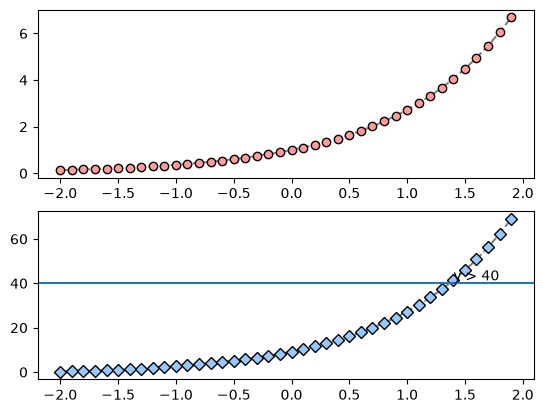

In [38]:
"""
Advanced 1 Continue to work on the plot of 2: Try to use the Figure/Axes instances 
directly instead of the pyplot convenience functions. Plot the cumulative sum of the 
data points as diamonds (marker "D") of a different color and make the connection 
between them a dashed gray line as well. Use the function ax.axhline to draw a solid 
black line at 𝑦=40. Use the function ax.annotate to point with an arrow to the first 
data point in the cumulative sum with 𝑦>40.
"""

import matplotlib as mpl

fig, ax = plt.subplots(2, 1)

origin = ax[0].plot(
    x, y,
    color = "grey", linestyle = "--",
    marker = "o", markerfacecolor = "#FF9B9B", markeredgecolor = "k",
    label = "Original Data"
)

cum_y = [sum(y[0:i+1]) for i in range(len(y))]

cumulate = ax[1].plot(
    x, cum_y,
    color = "grey", linestyle = "--",
    marker = "D", markerfacecolor = "#97C9FF", markeredgecolor = "k"
)

ax[1].axhline(40)

for i, value in enumerate(cum_y, 0):
    if value > 40:
        ax[1].annotate("y > 40", xy = (x[i], cum_y[i]))
        arrowprops = dict(arrowstyle = "->")
        break


[Text(0.5, 0, '$x$'), Text(0, 0.5, '$y$')]

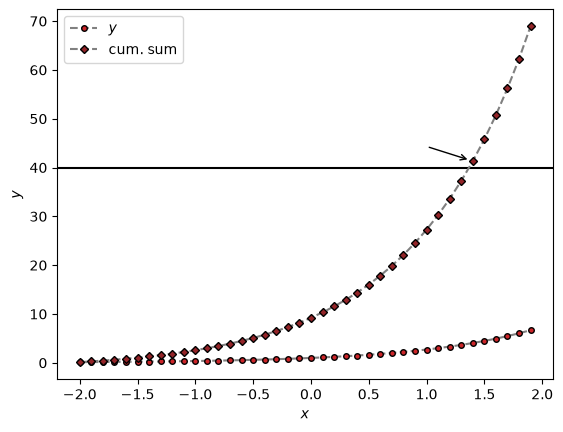

In [ ]:
""" 
Solution for Advanced 1
"""

# Use a function to find the first value over the threschold (40)
def find_point(seq, threshold=40):
    """Find threshold crossing point

    Use this function to find the first point in a sequence larger
    than a given threshold.

    Returns:
       Point index
    """

    for c, i in enumerate(seq):
        if i > threshold:
            return c

cumsum = [sum(y[:i]) for i, _ in enumerate(y, 1)]

# Draw the plots
fig, ax = plt.subplots()
ax.plot(
    x, y,
    markersize=4,
    marker="o", markeredgecolor="k", markerfacecolor="#cc2529",
    linestyle="--", color="gray",
    label="$y$"
    )
ax.plot(
    x, cumsum,
    markersize=4,
    marker="D", markeredgecolor="k", markerfacecolor="#922428",
    linestyle="--", color="gray",
    label="cum. sum"
    )

ax.legend()

ax.axhline(40, color="k", zorder=0)

crossing_point = find_point(cumsum)
ax.annotate( 

    # No text
    "",

    # position of annotation
    xy=(x[crossing_point], cumsum[crossing_point]),

    # Starting point of arrow
    xytext=(x[crossing_point] - 0.4, cumsum[crossing_point] + 3),

    # Type of arrow and distance from arrow to the point
    arrowprops={"arrowstyle": "->", "shrinkB": 4}
    )

# Setting label of axis
ax.set(**{
    "xlabel": "$x$",
    "ylabel": "$y$",
    })